# Lucas-Kanade Tracking

A textured surface translates by a known integer displacement between two frames. Track corners and measure where they land.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Motion estimator

An eight-pixel border is excluded from scoring to avoid wrap-around effects.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from gallery.vision import translated_texture


def estimate(before, after):
    mask = np.zeros_like(before)
    mask[8:-8, 8:-8] = 255
    start = cv2.goodFeaturesToTrack(before, 90, 0.015, 5, mask=mask)
    end, valid, _ = cv2.calcOpticalFlowPyrLK(
        before, after, start, None, winSize=(15, 15), maxLevel=2
    )
    ok = valid.ravel().astype(bool)
    return start[ok, 0], end[ok, 0] - start[ok, 0], len(start)

## Endpoint error

Twenty-four independent textures and translations contribute to the numerical summary.

Mean endpoint error: 0.005 px | Median: 0.000 px
Within 1 px: 100.0% | Valid fraction: 100.0%


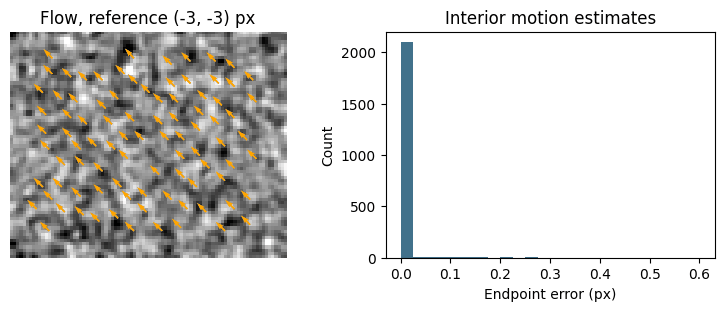

In [3]:
errors = []
available = 0
for seed in range(61, 85):
    before, after, target = translated_texture(seed)
    points, motion, count = estimate(before, after)
    errors.extend(np.linalg.norm(motion - target, axis=1))
    available += count
errors = np.array(errors)
print(f"Mean endpoint error: {errors.mean():.3f} px | Median: {np.median(errors):.3f} px")
print(f"Within 1 px: {(errors<1).mean():.1%} | Valid fraction: {len(errors)/available:.1%}")
fig, (a, b) = plt.subplots(1, 2, figsize=(7.4, 3), constrained_layout=True)
a.imshow(before, cmap="gray")
step = max(1, len(points) // 95)
p, v = points[::step], motion[::step]
a.quiver(p[:, 0], p[:, 1], v[:, 0], v[:, 1], color="orange", angles="xy", scale_units="xy", scale=1)
a.set_title(f"Flow, reference ({target[0]}, {target[1]}) px")
a.axis("off")
b.hist(errors, bins=24, color="#41718b")
b.set(xlabel="Endpoint error (px)", ylabel="Count", title="Interior motion estimates")
plt.show()

## Reading the result

A straight translation provides exact ground truth. Occlusion, lighting changes and a moving camera would require additional tests.

## References

[Lucas and Kanade, An Iterative Image Registration Technique (1981)](https://www.ri.cmu.edu/publications/an-iterative-image-registration-technique-with-an-application-to-stereo-vision-ijcai/)

[OpenCV, motion analysis and object tracking](https://docs.opencv.org/4.x/dc/d6b/group__video__track.html)

[Image and video generators and evaluation](../../../gallery/vision.py)